In [1]:
# 1. Package Installation (Run if needed)
# %pip install qiskit qiskit-machine-learning qiskit-aer scikit-learn pandas seaborn matplotlib

In [2]:
# ==========================================
# 2. Standard & Data Science Imports
# ==========================================
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warnings for clean output
warnings.filterwarnings('ignore')

# Set Elegant Plot Style (Matplotlib + Seaborn)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

# ==========================================
# 3. Machine Learning & Metrics
# ==========================================
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score, 
    classification_report, 
    confusion_matrix
)
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

# ==========================================
# 4. Qiskit & QML Components
# ==========================================
from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit_machine_learning.algorithms.classifiers import VQC
from qiskit_algorithms.optimizers import COBYLA
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

print("✓ Environment successfully configured for QML vs. Classical SVM Benchmarking!")

✓ Environment successfully configured for QML vs. Classical SVM Benchmarking!


Loading MNIST dataset...
✓ PCA Finished: 784 dimensions -> 4 components
✓ Total Retained Variance: 54.85%


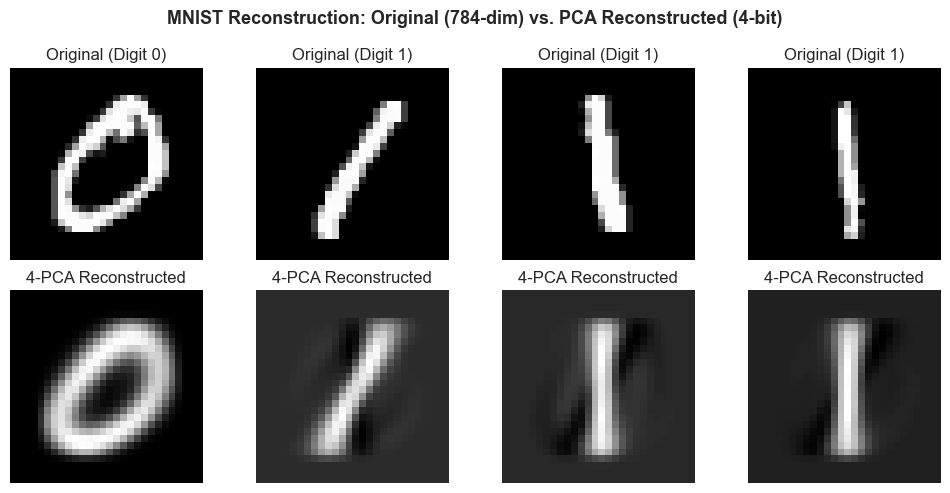

✓ Balanced Train Set: 900 samples | Test Set: 100 samples


In [3]:
# ==========================================
# Cell 2: Data Preparation, Reconstruction & Scaling
# ==========================================

# 1. Load MNIST Dataset
print("Loading MNIST dataset...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X_raw, y_raw = mnist.data, mnist.target

# 2. Filter Binary Classes ('0' and '1')
binary_mask = (y_raw == '0') | (y_raw == '1')
X_filtered, y_filtered = X_raw[binary_mask], y_raw[binary_mask].astype(int)

# 3. PCA Dimensionality Reduction (784 -> 4)
n_components = 4
pca = PCA(n_components=n_components, random_state=42)
X_pca = pca.fit_transform(X_filtered)

explained_var = np.sum(pca.explained_variance_ratio_) * 100
print(f"✓ PCA Finished: 784 dimensions -> {n_components} components")
print(f"✓ Total Retained Variance: {explained_var:.2f}%")

# 4. Feature Scaling [0, pi] for Quantum Encoding
scaler = MinMaxScaler(feature_range=(0, np.pi))
X_scaled = scaler.fit_transform(X_pca)

# 5. Train-Test Split (Balanced & Stratified)
# (ปรับขนาดตัวเลขตามที่คุณเลือกได้เลยครับ เช่น Train 300 / Test 100)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, 
    y_filtered, 
    train_size=900, 
    test_size=100, 
    stratify=y_filtered, 
    random_state=42
)

# 6. Data Visualization: Original vs. Reconstructed Images (4-PCA)
X_reconstructed = pca.inverse_transform(X_pca[:4])

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
fig.suptitle("MNIST Reconstruction: Original (784-dim) vs. PCA Reconstructed (4-bit)", fontsize=13, fontweight='bold')

for i in range(4):
    # Original Image
    axes[0, i].imshow(X_filtered[i].reshape(28, 28), cmap='gray')
    axes[0, i].set_title(f"Original (Digit {y_filtered[i]})")
    axes[0, i].axis('off')
    
    # Reconstructed Image
    axes[1, i].imshow(X_reconstructed[i].reshape(28, 28), cmap='gray')
    axes[1, i].set_title("4-PCA Reconstructed")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

print(f"✓ Balanced Train Set: {X_train.shape[0]} samples | Test Set: {X_test.shape[0]} samples")

✓ Quantum Circuit Architecture Defined Successfully!
• Total Qubits: 4
• Total Trainable Parameters: 16
• Circuit Depth: 47


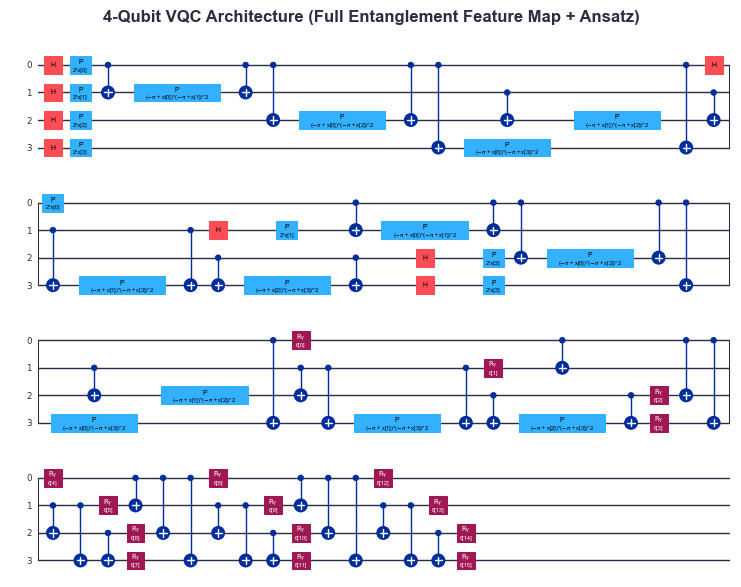

In [4]:
# ==========================================
# Cell 3: Quantum Circuit Architecture Design (Full Entanglement)
# ==========================================

num_qubits = 4

# 1. Feature Map & Ansatz with Full Entanglement
feature_map = zz_feature_map(feature_dimension=num_qubits, reps=2, entanglement='full')
ansatz = real_amplitudes(num_qubits=num_qubits, reps=3, entanglement='full')
vqc_circuit = feature_map.compose(ansatz)

# 2. Display Circuit Metrics
print("✓ Quantum Circuit Architecture Defined Successfully!")
print(f"• Total Qubits: {vqc_circuit.num_qubits}")
print(f"• Total Trainable Parameters: {ansatz.num_parameters}")
print(f"• Circuit Depth: {vqc_circuit.depth()}")

# 3. Customized Circuit Style
style_config = {
    "backgroundcolor": "#FFFFFF",
    "linecolor": "#2B2D42",
    "textcolor": "#2B2D42",
    "gatefacecolor": "#8D99AE",
    "barrierfacecolor": "#EDF2F4",
    "fontsize": 10,
    "subfontsize": 8
}

# 4. Corrected Visualization (ส่ง ax เข้าไปเพื่อป้องกันกราฟว่างเปล่า)
fig, ax = plt.subplots(figsize=(12, 6))
vqc_circuit.draw('mpl', style=style_config, ax=ax)
ax.set_title("4-Qubit VQC Architecture (Full Entanglement Feature Map + Ansatz)", 
             fontsize=12, fontweight='bold', pad=15, color='#2B2D42')

plt.tight_layout()
plt.show()

In [6]:
# ==========================================
# Cell 4: Model Training & Benchmarking Setup (Fixed)
# ==========================================

from qiskit.primitives import StatevectorSampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Lists to collect Loss during Quantum Training
vqc_loss_history = []

def vqc_callback(weights, obj_value):
    vqc_loss_history.append(obj_value)

# ------------------------------------------
# 1. Define Explicit Primitives & PassManager
# ------------------------------------------
sampler = StatevectorSampler()
pass_manager = generate_preset_pass_manager(optimization_level=1)

# ------------------------------------------
# 2. Train Quantum VQC Model (Ideal Simulator)
# ------------------------------------------
print("[1/2] Training Quantum VQC (Ideal Simulator)...")
optimizer = COBYLA(maxiter=100)

vqc = VQC(
    sampler=sampler,
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=optimizer,
    pass_manager=pass_manager,
    callback=vqc_callback
)

start_time = time.time()
vqc.fit(X_train, y_train)
vqc_train_time = time.time() - start_time
print(f"✓ VQC Training Complete in {vqc_train_time:.2f} seconds!")

# ------------------------------------------
# 3. Train Classical SVM Baseline (RBF Kernel)
# ------------------------------------------
print("\n[2/2] Training Classical Support Vector Machine (SVM)...")
svm = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)

start_time = time.time()
svm.fit(X_train, y_train)
svm_train_time = time.time() - start_time
print(f"✓ Classical SVM Training Complete in {svm_train_time:.4f} seconds!")

# ------------------------------------------
# 4. Model Predictions on Test Set
# ------------------------------------------
print("\nGenerating Predictions on Test Set...")
y_pred_vqc = vqc.predict(X_test)
y_pred_svm = svm.predict(X_test)

print("✓ All Predictions Ready for Evaluation Matrix!")

[1/2] Training Quantum VQC (Ideal Simulator)...
✓ VQC Training Complete in 445.58 seconds!

[2/2] Training Classical Support Vector Machine (SVM)...
✓ Classical SVM Training Complete in 0.0050 seconds!

Generating Predictions on Test Set...
✓ All Predictions Ready for Evaluation Matrix!


             FINAL BENCHMARKING METRICS MATRIX (MNIST 4-BIT)            


,Accuracy (%),Precision,Recall,F1-Score (Macro),Training Time (s)
Quantum VQC (Ideal),82.0,0.82934,0.814532,0.816401,445.585
Classical SVM (RBF),100.0,1.00000,1.000000,1.000000,0.005


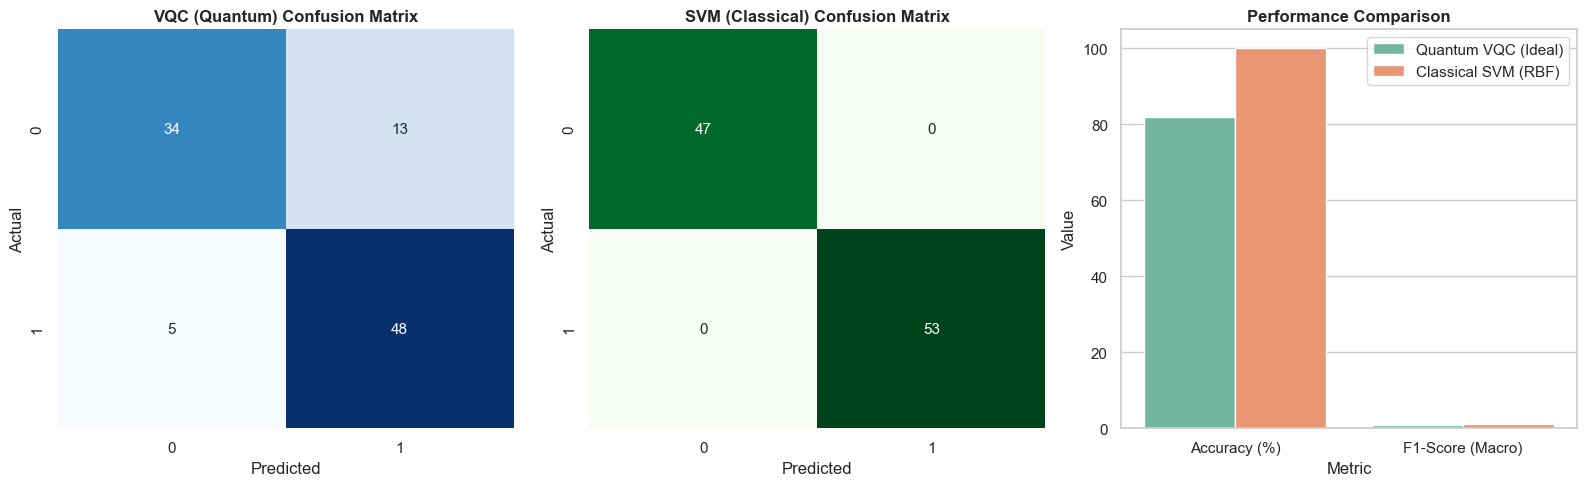

In [7]:
# ==========================================
# Cell 5: Final Metrics Matrix & Visualizations
# ==========================================

# 1. Compute Classical Metrics
def get_metrics(y_true, y_pred, train_time):
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision": precision_score(y_true, y_pred, average='macro'),
        "Recall": recall_score(y_true, y_pred, average='macro'),
        "F1-Score (Macro)": f1_score(y_true, y_pred, average='macro'),
        "Training Time (s)": round(train_time, 3)
    }

metrics_vqc = get_metrics(y_test, y_pred_vqc, vqc_train_time)
metrics_svm = get_metrics(y_test, y_pred_svm, svm_train_time)

# 2. Build Metrics Comparison Table
df_metrics = pd.DataFrame([metrics_vqc, metrics_svm], index=['Quantum VQC (Ideal)', 'Classical SVM (RBF)'])

print("=========================================================================")
print("             FINAL BENCHMARKING METRICS MATRIX (MNIST 4-BIT)            ")
print("=========================================================================")
display(df_metrics)

# 3. Visualization: Side-by-Side Confusion Matrix & Metric Bar Chart
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: VQC Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_vqc), annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title("VQC (Quantum) Confusion Matrix", fontweight='bold')
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Plot 2: SVM Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title("SVM (Classical) Confusion Matrix", fontweight='bold')
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

# Plot 3: Accuracy & F1 Comparison
df_plot = df_metrics[['Accuracy (%)', 'F1-Score (Macro)']].reset_index()
df_plot_melted = pd.melt(df_plot, id_vars='index', var_name='Metric', value_name='Value')

sns.barplot(data=df_plot_melted, x='Metric', y='Value', hue='index', palette='Set2', ax=axes[2])
axes[2].set_title("Performance Comparison", fontweight='bold')
axes[2].set_ylim(0, 105)
axes[2].legend(title="")

plt.tight_layout()
plt.show()